# AmBe source around a nanoguide: neutron, gamma and scatter contributions

**The measurement.** A nanoguide (scintillating EJ-200-type fibres in PMMA, 50 % of each by
volume; 10 mm × 10 mm × 100 mm, fibres along the length) is viewed end-on through the
LumaCam microscope. An AmBe source sits beside it, perpendicular to the long axis, at
several azimuths. Recoil-proton tracks projected on the end face show where the neutrons
came from. Some events have two light spots about 9 mm apart, and the question is whether
those are one neutron scattering twice.

**What this notebook does.** It simulates the source at eight azimuths with G4LumaCam
(branch `nanoguide`), once with neutrons and once with the 4.44 MeV gammas, and sorts the
light by where it came from: neutrons whose light comes from their first interaction in
the guide, neutrons whose light comes after a scatter, neutrons that leave several
separated clusters (they scattered twice or more), gammas with one or several clusters,
and coincidences of two source particles (a neutron with its own gamma, or two unrelated
decays). It does this with the Geant4 truth on the end face, then for what the camera
records (microscope, detection efficiency), and it runs EMPIR with the settings used for
the nanoguide data.

**How the guide is simulated.** Scintillation photons are not tracked through the guide:
each photon born inside the fibres' trapping cone towards the viewed end
(cos θ ≥ n_clad/n_core = 1.49/1.58) is moved to the end face at its birth position (x, y),
delayed by its path along the fibre, and leaves the face refracted into air. The microscope
images that face.

## Summary

For the setup assumed below (source 50 mm from the guide axis and halfway along it,
0.6 gammas per neutron with no lead in between, microscope at f/8), with 200 000 neutrons
and 120 000 gammas at each of eight azimuths:

- **The recoils show the source direction.** At every azimuth the mean direction of the
  recoil tracks on the end face is within 1° of pointing away from the source, and with the
  few photons the camera records, the axis of compact multi-photon events still follows it
  (sections 3 and 7).
- **What makes the light.** Of the events with a visible cluster (at least 20 guided photons
  on the end face), 70 % are one recoil from the neutron's first interaction, 6 % come after
  a scatter (for example on carbon first), 1.5 % are neutrons that leave two or more separated
  clusters, and 23 % are 4.44 MeV gammas (section 4).
- **Separate interactions 8–10 mm apart are mostly neutron double scatters**: 76 %, then
  gammas 19 %, a neutron with its own gamma 5 %, and accidental coincidences 0.2 %
  (section 6).
- **What the camera records 8–10 mm apart is mostly gammas.** A gamma's Compton electron
  spreads its light over millimetres (median rms 1 mm, against 0.02 mm for a recoil proton),
  and with one to three detected photons per event, two photons of one electron track can lie
  9 mm apart. Of the events whose detected photons span 8–10 mm, 82 % are one gamma
  interaction, 9 % a gamma with several, and 8 % neutron double scatters. For two compact
  spots 8–10 mm apart (40 simulated events) the shares are 85 %, 10 % and 5 % (sections 5
  and 7).
- **So a 9 mm event is more likely a gamma than a neutron scattering twice.** There was no
  shielding in the measurement; the gamma share scales with `GAMMA_PER_NEUTRON` (a literature
  value). A next step is to check whether the photons between the two spots (an electron
  track) tell them apart.
- **EMPIR.** The nanoguide data were reduced with the PTB `parameterSettings.json` (2 px and
  50 ns from pixels to photons, 2 px and 100 ns from photons to events). At 39 µm per pixel,
  EMPIR events are single photons (96 % in the simulation); pairs and tracks come from grouping
  EMPIR events in time, which gives as many groups as grouping the detected photons (section 8).

## Setup

Paths and parameters. The values marked *assumed* are not known for the measurement and
should be set to the real ones: they change the rates, and the gamma share depends on them.

In [1]:
import json, os, subprocess, sys, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Paths (edit for your machine). The notebook lives in <G4LumaCam>/notebooks/nanoguide.
REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
import lumacam
from lumacam.nanoguide import MICROSCOPE_ZFINE, cluster_pairs, light_clusters

EXE = Path(os.environ.get("LUMACAM_EXE", REPO / "build" / "lumacam"))      # nanoguide build
EMPIR_DIR = Path(os.environ.get("EMPIR_PATH", "/work/Programs/lumacam_measurementcontrol"))
EMPIR_SETTINGS = Path("/work/nuclear/60R/data/parameterSettings.json")    # used for the nanoguide data (copy in section 8)
ARCHIVE = Path("archive")                                                 # simulation output (cached)

# Source and guide
AZIMUTHS = [0, 45, 90, 135, 180, 225, 270, 315]  # deg, source direction from the guide axis (end-face x-y, from +x)
DISTANCE = 50.0             # mm, source to guide axis                                (assumed)
DEPTH = 50.0                # mm, source position from the viewed end face           (assumed: halfway)
N_NEUTRONS = 200_000        # simulated neutrons per azimuth (all emitted towards the guide)
GAMMA_PER_NEUTRON = 0.6     # 4.44 MeV gammas per AmBe neutron (literature value); no lead in the measurement
SOURCE_STRENGTH = 8e4       # neutrons/s into 4 pi                                    (assumed)

# Analysis
MERGE_MM = 1.0              # emitting particles (truth) or photons (camera) closer than this form one cluster
MIN_PHOTONS = 20            # truth cluster threshold: guided photons on the end face (before the lens)
FAR_MM = (8.0, 10.0)        # separation window of the "9 mm" events
COINC_NS = 100.0            # coincidence window (EMPIR photon2event dTime)

# Camera
FNUMBER = 8.0               # microscope aperture (Lens default)                      (assumed)
QE = 0.241                  # detected fraction of the photons entering the lens (calibrated v0.6 value)
PIXEL_MM = 10.0 / 256       # microscope field of view / pixels

N_JOBS = os.cpu_count()
assert EXE.exists(), f"build the nanoguide branch first: {EXE}"

In [2]:
# One colour per contribution, the same in every figure; line style by particle
COLORS = {
    "n, first interaction": "#2a78d6",
    "n, after a scatter":   "#eb6834",
    "n, several clusters":  "#1baf7a",
    "γ, one cluster":       "#eda100",
    "γ, several clusters":  "#e87ba4",
    "n + its own γ":        "#008300",
    "accidental":           "#4a3aa7",
}
STYLES = {k: "-" if k.startswith("n,") else "--" if k.startswith("γ") else ":" if k.startswith("n +") else "-."
          for k in COLORS}
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", [SURFACE, "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10, "lines.linewidth": 2,
})

def lines(ax, data, bins, kinds, weight="per_million", **kw):
    # one step line per contribution
    for k in kinds:
        s = data[data.kind == k]
        if len(s):
            h = np.histogram(s[kw.get("col", "distance")], bins, weights=s[weight])[0]
            if kw.get("density"):
                h = h / np.diff(bins)
            ax.stairs(h, bins, color=COLORS[k], ls=STYLES[k], label=k)

## 1. Simulations

For every azimuth there is a neutron run and a gamma run. The source emits isotropically
into the window of directions that just covers the guide, so every simulated particle heads
for it; `solid_angle_fraction` converts simulated particles back to source emissions. The
gamma run has `GAMMA_PER_NEUTRON` times as many particles as the neutron run and both are
spread over the same time at the source rate, so together they are one measurement of
`T` seconds per azimuth. Runs are cached in `archive/` and only rerun when their macro
changes (about 6 minutes for all 16 on 16 cores).

In [3]:
def run_dir(particle, az):
    return ARCHIVE / f"{particle}_az{az:03d}"

def config(particle, az):
    gamma = particle == "gamma"
    return lumacam.Config.ambe_nanoguide(
        azimuth=az, distance=DISTANCE, depth=DEPTH, particle=particle,
        source_strength=SOURCE_STRENGTH * (GAMMA_PER_NEUTRON if gamma else 1),
        num_events=round(N_NEUTRONS * (GAMMA_PER_NEUTRON if gamma else 1)))

def simulate(particle, az, seed):
    d = run_dir(particle, az)
    d.mkdir(parents=True, exist_ok=True)
    config(particle, az).write(str(d / "new.mac"))
    body = (d / "new.mac").read_text()
    if (d / "done").exists() and (d / "body.mac").read_text() == body:
        return "cached"
    (d / "body.mac").write_text(body)
    (d / "macro.mac").write_text(f"/random/setSeeds {seed} {seed + 7919}\n" + body)
    with open(d / "log.txt", "w") as log:
        subprocess.run([str(EXE), "macro.mac"], cwd=d, stdout=log, stderr=subprocess.STDOUT, check=True)
    (d / "done").write_text("")
    return "simulated"

jobs = [(p, az, 1000 * i + k) for i, az in enumerate(AZIMUTHS) for k, p in enumerate(("neutron", "gamma"), 1)]
t0 = time.time()
with ThreadPoolExecutor(N_JOBS) as pool:
    status = list(pool.map(lambda j: simulate(*j), jobs))
print(f"{status.count('simulated')} runs simulated, {status.count('cached')} cached ({time.time() - t0:.0f} s)")

FRACTION = config("neutron", 0).solid_angle_fraction
N_SOURCE = N_NEUTRONS / FRACTION            # source neutrons per azimuth
T = N_SOURCE / SOURCE_STRENGTH              # measurement time per azimuth, s
PER_MILLION = 1e6 / (N_SOURCE * len(AZIMUTHS))   # weight of one event, pooled over azimuths
print(f"emission window: {FRACTION:.4f} of 4 pi -> {N_SOURCE:.3g} source neutrons = {T:.0f} s per azimuth")

0 runs simulated, 16 cached (0 s)
emission window: 0.0370 of 4 pi -> 5.4e+06 source neutrons = 67 s per azimuth


## 2. From photons to light clusters

Every photon on the end face belongs to the charged particle that emitted it. Particles of
one event whose light centroids lie within `MERGE_MM` of each other form one **cluster**
(a recoil proton and its delta electrons count once). A cluster counts as visible with at
least `MIN_PHOTONS` guided photons on the end face, before the lens (section 7 adds the
lens and the detection efficiency).

Each cluster carries the Geant4 truth `n_int`: which interaction of the source particle in
the guide produced its light (1 = the first, 2 or more = after a scatter), and `rms`, the
spread of its photons on the face. Times are relative to the emission in the source; only
prompt clusters, within `COINC_NS` of the emission, are kept (later light comes from
activation decays in the guide and arrives as separate events).

In [4]:
def photon_files(d):
    for f in sorted((d / "SimPhotons").glob("sim_data_*.csv")):
        df = pd.read_csv(f)
        if len(df):
            yield df

def clusters_of(particle, az):
    d = run_dir(particle, az)
    out = d / f"clusters_merge{MERGE_MM}_v2.csv.gz"
    if out.exists() and out.stat().st_mtime > (d / "done").stat().st_mtime:
        return pd.read_csv(out)
    parts = []
    for df in photon_files(d):
        cl = light_clusters(df, merge=MERGE_MM, min_photons=1)
        cl["t"] -= cl["neutron_id"].map(df.groupby("neutron_id")["pulse_time_ns"].first())
        parts.append(cl)
    cl = pd.concat(parts, ignore_index=True)
    cl.to_csv(out, index=False)
    return cl

clusters = pd.concat([clusters_of(p, az).assign(particle=p, azimuth=az)
                      for az in AZIMUTHS for p in ("neutron", "gamma")], ignore_index=True)
prompt = clusters.t < COINC_NS
bright = clusters[prompt & (clusters.n_photons >= MIN_PHOTONS)].copy()
print(f"{len(clusters):,} clusters, {len(bright):,} prompt with >= {MIN_PHOTONS} photons "
      f"({(~prompt).sum()} delayed clusters left out)")
bright.head()

228,537 clusters, 91,868 prompt with >= 20 photons (7 delayed clusters left out)


,neutron_id,cluster,x,y,rms,n_photons,t,particles,energy,px,py,pz,n_int,particle,azimuth
5,25,0,-4.942925,4.861219,0.017426,68,2.240713,proton,0.0171,-4.9174,4.8771,57.3932,1,neutron,0
10,39,0,0.441478,4.790747,0.006662,32,3.701347,proton,0.0904,0.4518,4.7872,32.4186,1,neutron,0
16,73,0,4.417520,-4.746730,0.008321,30,2.988937,proton,2.0626,4.4302,-4.7552,31.0211,1,neutron,0
20,114,0,-2.792923,-4.528870,0.020069,103,2.100679,proton,0.4040,-2.7644,-4.5494,79.7020,1,neutron,0
21,116,0,-0.821357,4.752038,0.018662,56,3.178596,proton,3.2448,-0.7912,4.7623,11.5261,1,neutron,0


## 3. Recoils point away from the source

The projected track of a cluster runs from the birth of its emitting particle to the
centroid of its light (which leans towards the Bragg peak). For neutrons, its direction on
the end face is the recoil direction. The rose plots show it for the clusters with a
projected track of at least 50 µm, split into light from the neutron's first interaction
and light after a scatter. The grey line marks the source.

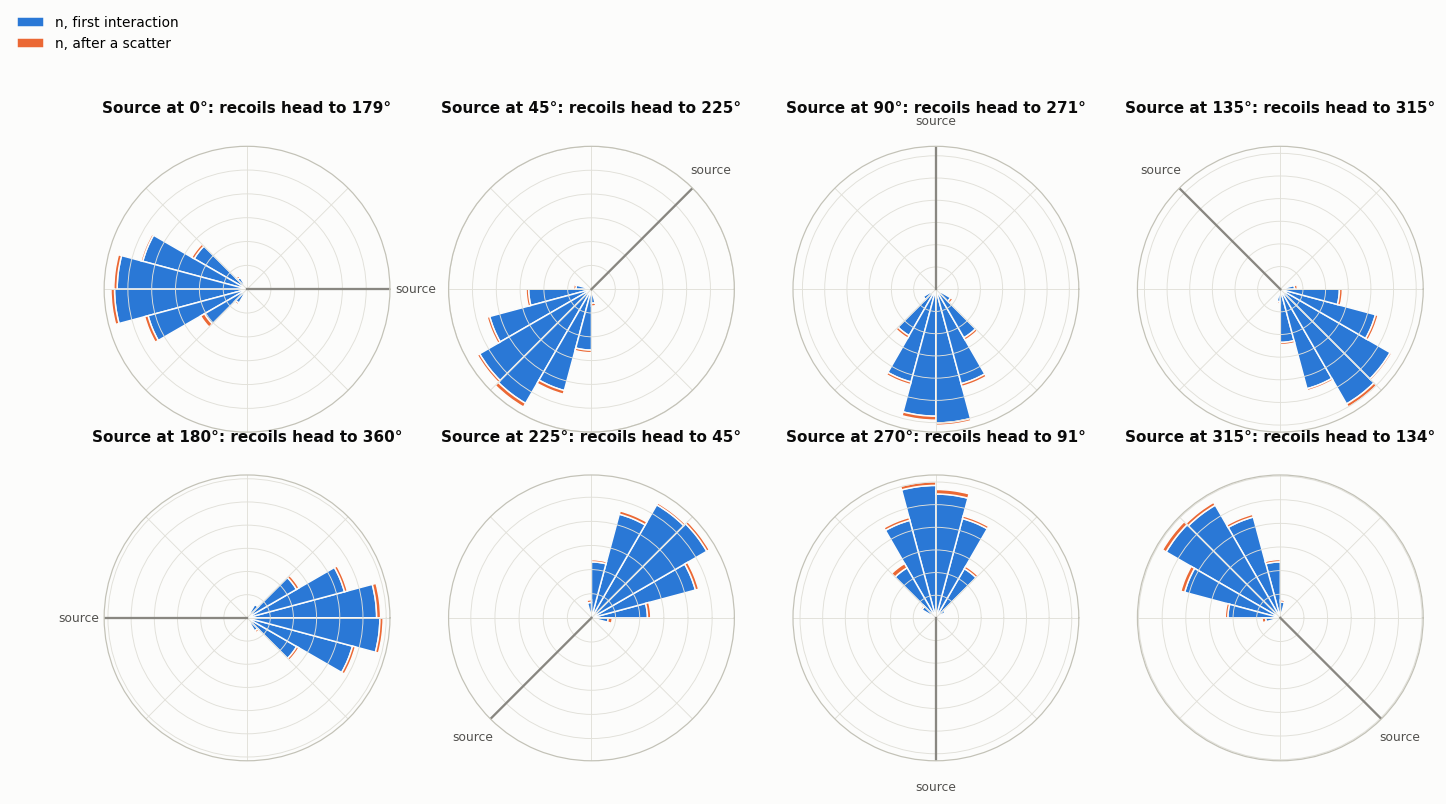

In [5]:
neutron = bright[bright.particle == "neutron"].copy()
neutron["track"] = np.hypot(neutron.x - neutron.px, neutron.y - neutron.py)
neutron["angle"] = np.degrees(np.arctan2(neutron.y - neutron.py, neutron.x - neutron.px)) % 360
tracks = neutron[neutron.track > 0.05]

edges = np.radians(np.arange(0, 361, 15))
fig, axes = plt.subplots(2, 4, figsize=(13, 7), subplot_kw={"projection": "polar"})
for ax, az in zip(axes.flat, AZIMUTHS):
    t = tracks[tracks.azimuth == az]
    first = np.histogram(np.radians(t.angle[t.n_int == 1]), edges)[0]
    after = np.histogram(np.radians(t.angle[t.n_int != 1]), edges)[0]
    w = np.diff(edges)
    ax.bar(edges[:-1], first, width=w, align="edge", color=COLORS["n, first interaction"],
           edgecolor=SURFACE, linewidth=1, label="n, first interaction")
    ax.bar(edges[:-1], after, width=w, align="edge", bottom=first, color=COLORS["n, after a scatter"],
           edgecolor=SURFACE, linewidth=1, label="n, after a scatter")
    top = (first + after).max() * 1.05
    ax.set_ylim(0, top)
    ax.plot([np.radians(az)] * 2, [0, top], color=MUTED, lw=1.5)
    ax.text(np.radians(az), top * 1.18, "source", color=INK2, ha="center", va="center", fontsize=8)
    mean = np.degrees(np.angle(np.exp(1j * np.radians(t.angle[t.n_int == 1])).mean())) % 360
    ax.set_title(f"Source at {az}°: recoils head to {mean:.0f}°", pad=22, fontsize=10)
    ax.set_yticklabels([]); ax.set_xticklabels([]); ax.grid(color=GRID)
axes.flat[0].legend(loc="upper left", bbox_to_anchor=(-0.35, 1.5), fontsize=9)
fig.tight_layout()
plt.show()

## 4. Contributions per azimuth

Each source particle that leaves at least one visible cluster is one event, sorted by its
truth: neutrons with one cluster from their first interaction, neutrons with one cluster
after a scatter, neutrons with several separated clusters, and gammas with one or several
clusters. The rates are per million source neutrons (the gammas included at
`GAMMA_PER_NEUTRON`); the table also gives them per hour at `SOURCE_STRENGTH`.

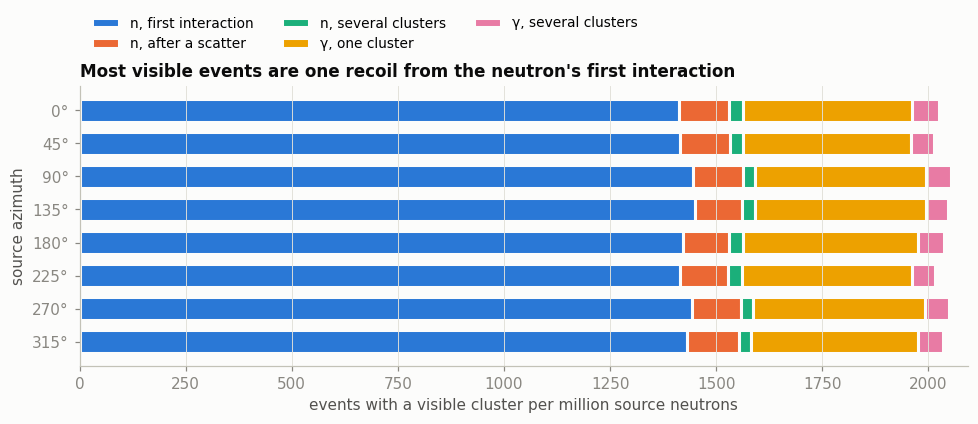

,per million source neutrons,per hour,share (%)
kind,,,
"n, first interaction",1429.3,411633.2,70.27
"n, after a scatter",115.2,33187.5,5.67
"n, several clusters",30.9,8902.0,1.52
"γ, one cluster",401.6,115652.9,19.74
"γ, several clusters",57.0,16430.4,2.80
all,2034.0,585806.0,100.00


In [6]:
events = (bright.groupby(["azimuth", "particle", "neutron_id"])
                .agg(n_clusters=("cluster", "size"), n_int=("n_int", "first")).reset_index())
is_n, several = events.particle == "neutron", events.n_clusters > 1
events["kind"] = np.select(
    [several & is_n, several, ~is_n, events.n_int == 1],
    ["n, several clusters", "γ, several clusters", "γ, one cluster", "n, first interaction"],
    default="n, after a scatter")
counts = events.pivot_table(index="azimuth", columns="kind", values="neutron_id", aggfunc="size", fill_value=0)
counts = counts[[k for k in COLORS if k in counts.columns]]
per_million = counts / N_SOURCE * 1e6

fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(per_million))
for k in per_million.columns:
    ax.barh([f"{az}°" for az in per_million.index], per_million[k], left=left, color=COLORS[k],
            edgecolor=SURFACE, linewidth=2, height=0.7, label=k)
    left += per_million[k].to_numpy()
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.02)
ax.set_xlabel("events with a visible cluster per million source neutrons")
ax.set_ylabel("source azimuth")
ax.set_title("Most visible events are one recoil from the neutron's first interaction", loc="left")
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.08), fontsize=9)
fig.tight_layout()
plt.show()

table = pd.DataFrame({"per million source neutrons": per_million.mean().round(1),
                      "per hour": (counts.mean() / T * 3600).round(1),
                      "share (%)": (100 * counts.sum() / counts.sum().sum()).round(2)})
table.loc["all"] = table.sum().round(2)
table

## 5. Gamma tracks are long, proton tracks are short

A recoil proton from an AmBe neutron stops within a fraction of a millimetre, but the
Compton electron of a 4.44 MeV gamma can carry up to 4.2 MeV and run for centimetres in
plastic. The spread of the light of each visible cluster on the end face shows it (the top
axis converts it to the length of a straight track, √12 × rms).

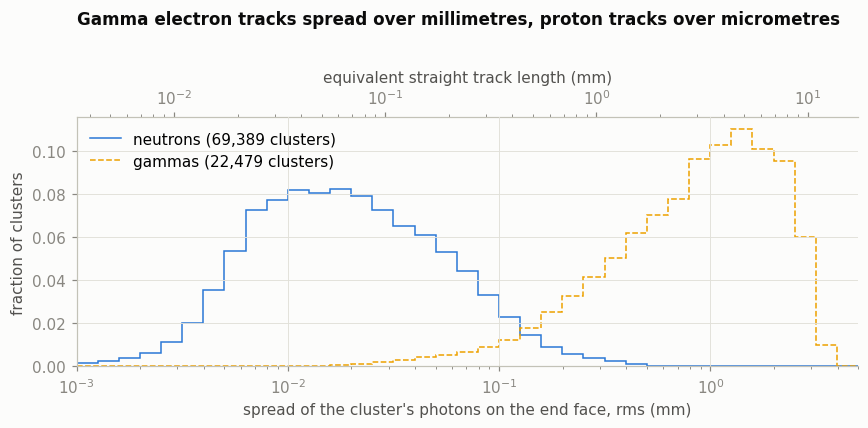

,median rms (mm),90 % below (mm)
particle,,
gamma,0.950,2.316
neutron,0.018,0.077


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(-3, np.log10(5), 38)
for p, k in (("neutron", "n, first interaction"), ("gamma", "γ, one cluster")):
    s = bright[bright.particle == p]
    ax.stairs(np.histogram(s.rms, bins)[0] / len(s), bins, color=COLORS[k], ls=STYLES[k],
              label=f"{p}s ({len(s):,} clusters)")
ax.set_xscale("log"); ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel("spread of the cluster's photons on the end face, rms (mm)")
ax.set_ylabel("fraction of clusters")
top = ax.secondary_xaxis("top", functions=(lambda r: r * 12 ** 0.5, lambda l: l / 12 ** 0.5))
top.set_xlabel("equivalent straight track length (mm)", color=INK2)
top.tick_params(colors=MUTED)
ax.set_title('Gamma electron tracks spread over millimetres, proton tracks over micrometres', loc="left", pad=30)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

spread = bright.groupby("particle").rms.quantile([0.5, 0.9]).unstack().rename(columns={0.5: "median rms (mm)", 0.9: "90 % below (mm)"})
spread.round(3)

## 6. Separate interactions: where pairs of clusters come from

Two clusters in one event can be a neutron scattering twice, a gamma, or two source
particles at once. Two of the latter are added here from the single-particle runs:

- **a neutron with its own gamma**: AmBe emits the 4.44 MeV gamma together with the
  neutron (for `GAMMA_PER_NEUTRON` of them). Both reach the guide independently, so their
  clusters are drawn from the neutron and the gamma events of the same azimuth, at the rate
  of both being visible from one decay;
- **accidental coincidences**: two unrelated events within ±`COINC_NS`, at the rate set
  by `SOURCE_STRENGTH`.

For every event the pair is the two clusters farthest apart, by their light centroids. The
time difference is that of the earliest photons of the two clusters (the gamma arrives a
few ns before its neutron). All azimuths are pooled.

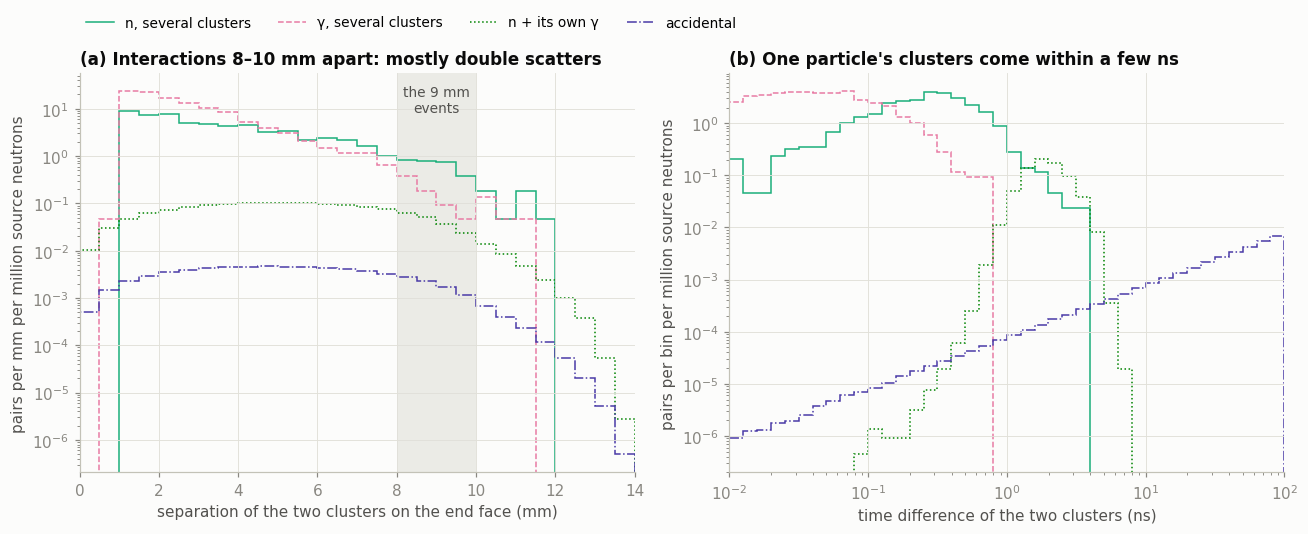

cluster pairs 8-10 mm apart (59 simulated neutron double scatters):


,per_million,per hour,share (%)
kind,,,
accidental,0.0040,1.1433,0.2200
n + its own γ,0.0872,25.1144,4.8325
"n, several clusters",1.3661,393.4224,75.7014
"γ, several clusters",0.3473,100.0226,19.2461


In [8]:
rng = np.random.default_rng(1)
pairs = []
for p, kind in (("neutron", "n, several clusters"), ("gamma", "γ, several clusters")):
    pr = cluster_pairs(bright[bright.particle == p].assign(neutron_id=lambda c: c.azimuth * 10**7 + c.neutron_id))
    pr = pr.loc[pr.groupby("neutron_id").distance.idxmax()]
    pairs.append(pd.DataFrame({"kind": kind, "distance": pr.distance, "dt": pr.dt.abs(), "weight": 1.0}))

M = 200_000  # sampled pairs per azimuth for the two coincidence contributions
lead = bright.sort_values("n_photons").groupby(["azimuth", "particle", "neutron_id"]).tail(1)
for az in AZIMUTHS:
    n = lead[(lead.azimuth == az) & (lead.particle == "neutron")]
    g = lead[(lead.azimuth == az) & (lead.particle == "gamma")]
    both = pd.concat([n, g])
    a, b = n.sample(M, replace=True, random_state=rng), g.sample(M, replace=True, random_state=rng)
    expected = len(n) * len(g) / N_SOURCE                      # decays with both particles visible
    pairs.append(pd.DataFrame({"kind": "n + its own γ", "distance": np.hypot(a.x.values - b.x.values, a.y.values - b.y.values),
                               "dt": np.abs(a.t.values - b.t.values), "weight": expected / M}))
    a, b = both.sample(M, replace=True, random_state=rng), both.sample(M, replace=True, random_state=rng)
    expected = len(both) ** 2 * COINC_NS * 1e-9 / T            # pairs within the window in T
    pairs.append(pd.DataFrame({"kind": "accidental", "distance": np.hypot(a.x.values - b.x.values, a.y.values - b.y.values),
                               "dt": rng.uniform(0, COINC_NS, M), "weight": expected / M}))
pairs = pd.concat(pairs, ignore_index=True)
pairs["per_million"] = pairs.weight * PER_MILLION

kinds = ["n, several clusters", "γ, several clusters", "n + its own γ", "accidental"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
lines(a1, pairs, np.arange(0, 14.5, 0.5), kinds, density=True)
lines(a2, pairs, np.logspace(-2, np.log10(COINC_NS), 41), kinds, col="dt")
for ax in (a1, a2):
    ax.set_yscale("log")
a1.axvspan(*FAR_MM, color=GRID, alpha=0.6, lw=0, zorder=0)
a1.text(np.mean(FAR_MM), 0.97, "the 9 mm\nevents", transform=a1.get_xaxis_transform(),
        ha="center", va="top", color=INK2, fontsize=9)
a1.set_xlim(0, 14)
a1.set_xlabel("separation of the two clusters on the end face (mm)")
a1.set_ylabel("pairs per mm per million source neutrons")
a1.set_title('(a) Interactions 8–10 mm apart: mostly double scatters', loc="left")
a2.set_xscale("log"); a2.set_xlim(1e-2, COINC_NS)
a2.set_xlabel("time difference of the two clusters (ns)")
a2.set_ylabel("pairs per bin per million source neutrons")
a2.set_title("(b) One particle's clusters come within a few ns", loc="left")
handles, labels = a1.get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, loc="upper left", bbox_to_anchor=(0.06, 1.06), fontsize=9)
fig.tight_layout()
plt.show()

far = pairs[pairs.distance.between(*FAR_MM)]
far_table = far.groupby("kind").agg(per_million=("per_million", "sum"))
far_table["per hour"] = far_table.per_million * 1e-6 * SOURCE_STRENGTH * 3600
far_table["share (%)"] = 100 * far_table.per_million / far_table.per_million.sum()
print(f"cluster pairs {FAR_MM[0]:g}-{FAR_MM[1]:g} mm apart "
      f"({(far.kind == 'n, several clusters').sum()} simulated neutron double scatters):")
far_table.round(4)

## 7. What the camera sees

The end-face photons go through the microscope (`Lens(kind="microscope")`, focused on the
end face at `MICROSCOPE_ZFINE`, aperture `FNUMBER`) and a fraction `QE` of those entering
the lens is detected. The neutron and gamma runs of one azimuth cover the same time, so
their detected photons are merged into one stream and split into events wherever two
photons are more than `COINC_NS` apart, without any spatial condition. Each event keeps
the truth of its photons: one source particle (sorted as above, *several clusters* meaning
photons from different interactions) or several (*accidental*). A neutron with its own
gamma is not in this stream, because the two runs are independent (section 6 gives its
share). Photon positions are pixel centres plus a uniform offset within the pixel, so
angles are not locked to the pixel grid.

In [9]:
def detected(particle, az):
    d = run_dir(particle, az)
    out = d / f"detected_f{FNUMBER}_qe{QE}.csv.gz"
    if out.exists() and out.stat().st_mtime > (d / "done").stat().st_mtime:
        return pd.read_csv(out)
    lens = lumacam.Lens(archive=str(d), kind="microscope", zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER, verbosity=0)
    r = lens.trace_rays(zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER, source="photons",
                        model_params={"photon_keep_fraction": QE}, seed=az, return_df=True,
                        progress_bar=False, verbosity=0, n_processes=N_JOBS)
    r = r.dropna(subset=["pixel_x"])[["pixel_x", "pixel_y", "toa2", "neutron_id", "id"]]
    truth = pd.concat([df[["neutron_id", "id", "parentName", "n_int"]] for df in photon_files(d)])
    r = r.merge(truth, on=["neutron_id", "id"], how="left")
    r.to_csv(out, index=False)
    return r

t0 = time.time()
photons = pd.concat([detected(p, az).assign(particle=p, azimuth=az)
                     for az in AZIMUTHS for p in ("neutron", "gamma")], ignore_index=True)
dither = np.random.default_rng(2).uniform(-0.5, 0.5, (len(photons), 2))
photons["x"] = (photons.pixel_x - 128.5 + dither[:, 0]) * PIXEL_MM
photons["y"] = (photons.pixel_y - 128.5 + dither[:, 1]) * PIXEL_MM
print(f"{len(photons):,} detected photons ({time.time() - t0:.0f} s)")

140,203 detected photons (0 s)


In [10]:
def camera_events(ph):
    ph = ph.sort_values("toa2").reset_index(drop=True)
    ph["event"] = (ph.toa2.diff() > COINC_NS).cumsum()
    ph["primary"] = ph.particle + ":" + ph.neutron_id.astype(str)
    ev = ph.groupby("event").agg(n_photons=("x", "size"), n_primaries=("primary", "nunique"),
                                 particle=("particle", "first"), n_ints=("n_int", "nunique"),
                                 n_int=("n_int", "first"))
    is_n, several = ev.particle == "neutron", ev.n_ints > 1
    ev["kind"] = np.select(
        [ev.n_primaries > 1, several & is_n, several, ~is_n, ev.n_int == 1],
        ["accidental", "n, several clusters", "γ, several clusters", "γ, one cluster", "n, first interaction"],
        default="n, after a scatter")
    ev["distance"], ev["spots"], ev["spot_distance"], ev["axis"] = 0.0, 0, 0.0, np.nan
    for e, g in ph[ph.event.map(ev.n_photons) > 1].groupby("event"):
        xy = g[["x", "y"]].to_numpy()
        d = np.hypot(*(xy[:, None] - xy[None]).transpose(2, 0, 1))
        ev.loc[e, "distance"] = d.max()
        # spots: photons chained within MERGE_MM; a compact spot has two or more photons
        lab = np.arange(len(g))
        for i, j in zip(*np.nonzero(np.triu(d < MERGE_MM, 1))):
            lab[lab == lab[j]] = lab[i]
        spots = [xy[lab == l].mean(0) for l in np.unique(lab) if (lab == l).sum() >= 2]
        ev.loc[e, "spots"] = len(spots)
        if len(spots) > 1:
            c = np.array(spots)
            ev.loc[e, "spot_distance"] = np.hypot(*(c[:, None] - c[None]).transpose(2, 0, 1)).max()
        if 0.1 <= d.max() <= 2.0:  # one compact recoil, long enough for an axis
            v = np.linalg.eigh(np.cov(xy.T))[1][:, -1]
            ev.loc[e, "axis"] = np.degrees(np.arctan2(v[1], v[0])) % 180
    return ev.reset_index()

cam = pd.concat([camera_events(photons[photons.azimuth == az]).assign(azimuth=az) for az in AZIMUTHS],
                ignore_index=True)
cam["per_million"] = PER_MILLION
summary = cam.groupby("kind").agg(events=("event", "size"), mean_photons=("n_photons", "mean"),
                                  max_photons=("n_photons", "max"))
summary.loc[[k for k in COLORS if k in summary.index]].round(2)

,events,mean_photons,max_photons
kind,,,
"n, first interaction",43977,1.94,14
"n, after a scatter",3771,1.51,12
"n, several clusters",928,3.19,14
"γ, one cluster",15468,2.90,16
"γ, several clusters",272,4.98,15
accidental,2,2.00,2


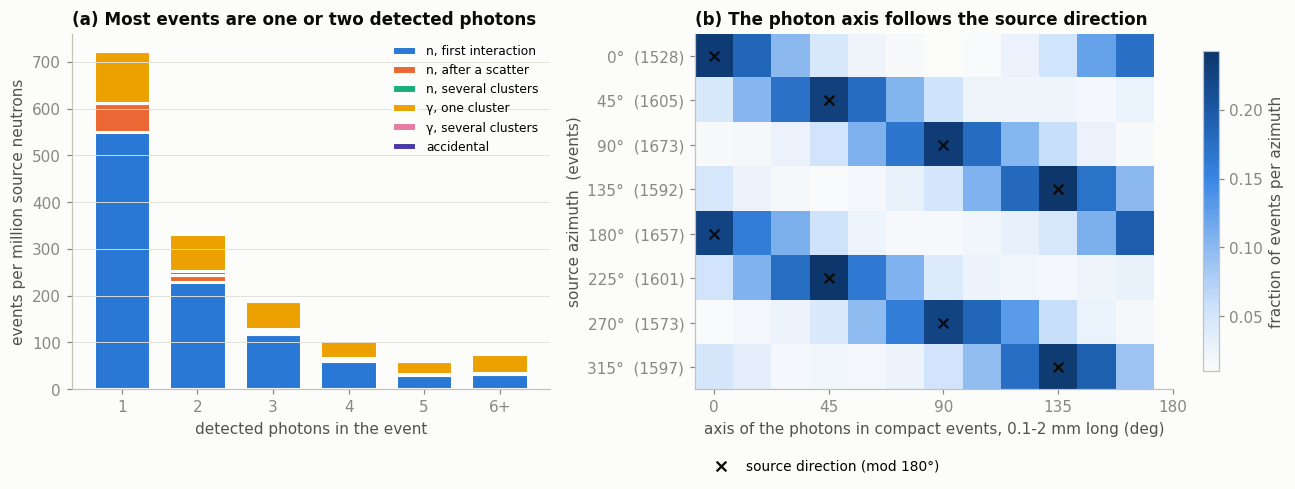

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
kinds = [k for k in COLORS if k in cam.kind.unique()]
nmax = 6
bottom = np.zeros(nmax)
for k in kinds:
    s = cam[cam.kind == k].n_photons.clip(upper=nmax)
    h = np.bincount(s, minlength=nmax + 1)[1:] * PER_MILLION
    a1.bar(np.arange(1, nmax + 1), h, bottom=bottom, color=COLORS[k], edgecolor=SURFACE, linewidth=2,
           width=0.75, label=k)
    bottom += h
a1.grid(axis="x", visible=False); a1.set_ylim(0, bottom.max() * 1.05)
a1.set_xticks(range(1, nmax + 1), [*map(str, range(1, nmax)), f"{nmax}+"])
a1.set_xlabel("detected photons in the event")
a1.set_ylabel("events per million source neutrons")
a1.set_title('(a) Most events are one or two detected photons', loc="left")
a1.legend(fontsize=8, loc="upper right")

ax_edges = np.arange(-7.5, 180, 15)          # bins centred on 0, 15, ..., 165 deg
ang = (cam.axis + 7.5) % 180 - 7.5
heat = np.array([np.histogram(ang[(cam.azimuth == az) & cam.axis.notna()], ax_edges)[0] for az in AZIMUTHS], float)
n_axis = heat.sum(axis=1)
heat /= n_axis[:, None]
im = a2.imshow(heat, aspect="auto", cmap=BLUES, extent=[ax_edges[0], ax_edges[-1], len(AZIMUTHS) - 0.5, -0.5])
a2.scatter([az % 180 for az in AZIMUTHS], range(len(AZIMUTHS)), marker="x", s=40, color=INK, lw=1.5,
           label="source direction (mod 180°)")
a2.set_yticks(range(len(AZIMUTHS)), [f"{az}°  ({int(n)})" for az, n in zip(AZIMUTHS, n_axis)]); a2.grid(False)
a2.set_xticks(range(0, 181, 45))
a2.set_xlabel("axis of the photons in compact events, 0.1-2 mm long (deg)")
a2.set_ylabel("source azimuth  (events)")
a2.set_title('(b) The photon axis follows the source direction', loc="left")
a2.legend(loc="upper left", bbox_to_anchor=(0, -0.16), fontsize=9)
fig.colorbar(im, ax=a2, label="fraction of events per azimuth", shrink=0.9)
fig.tight_layout()
plt.show()

Two views of the "9 mm events" at the camera: **(a)** any two detected photons of one event
that far apart, and **(b)** two compact spots that far apart, each with at least two photons
within `MERGE_MM`, which is closer to how such an event looks by eye.

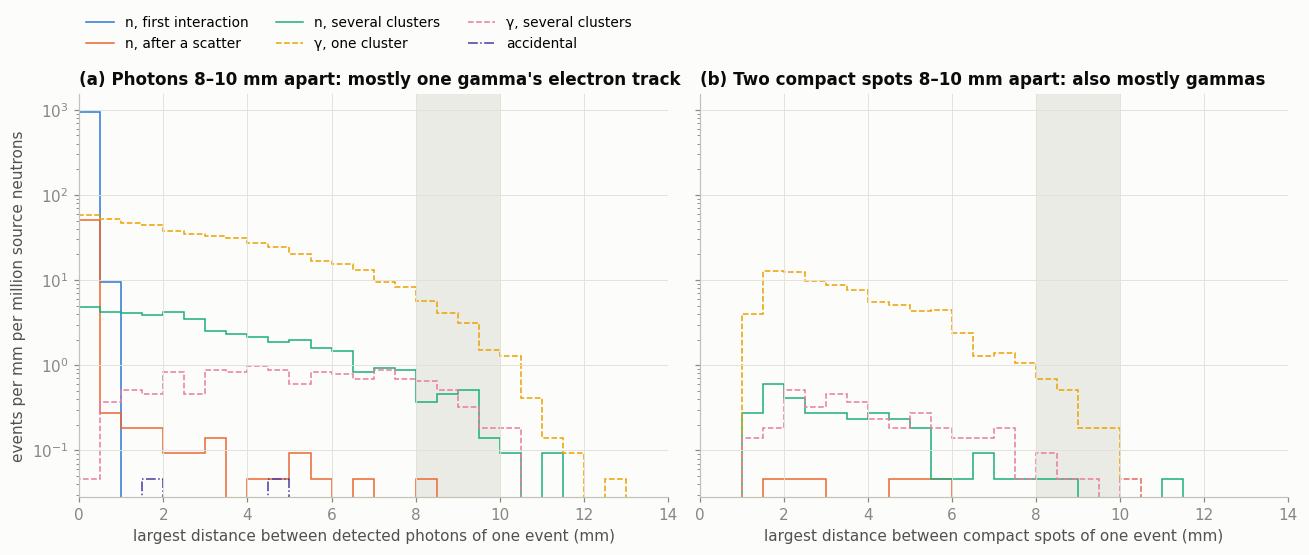

events  per hour  share (%)
                      kind                                            
(a) any two photons   γ, one cluster          310   2067.13      81.79
                      γ, several clusters      36    240.05       9.50
                      n, several clusters      32    213.38       8.44
                      n, after a scatter        1      6.67       0.26
(b) two compact spots γ, one cluster           34    226.72      85.00
                      γ, several clusters       4     26.67      10.00
                      n, several clusters       2     13.34       5.00

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
bins = np.arange(0, 14.5, 0.5)
kinds = [k for k in COLORS if k in cam.kind.unique()]
lines(a1, cam[cam.n_photons > 1], bins, kinds, density=True)
lines(a2, cam[cam.spots > 1].assign(distance=lambda c: c.spot_distance), bins, kinds, density=True)
for ax, title, xl in ((a1, "(a) Photons 8–10 mm apart: mostly one gamma's electron track", "largest distance between detected photons of one event (mm)"),
                      (a2, '(b) Two compact spots 8–10 mm apart: also mostly gammas', "largest distance between compact spots of one event (mm)")):
    ax.set_yscale("log"); ax.set_xlim(0, 14)
    ax.axvspan(*FAR_MM, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.set_xlabel(xl); ax.set_title(title, loc="left")
a1.set_ylabel("events per mm per million source neutrons")
handles, labels = a1.get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper left", bbox_to_anchor=(0.06, 1.1), fontsize=9)
fig.tight_layout()
plt.show()

def far_share(sel, col):
    f = cam[sel & cam[col].between(*FAR_MM)].kind.value_counts().rename("events").to_frame()
    f["per hour"] = f.events / (T * len(AZIMUTHS)) * 3600
    f["share (%)"] = 100 * f.events / f.events.sum()
    return f
far_cam = pd.concat({"(a) any two photons": far_share(cam.n_photons > 1, "distance"),
                     "(b) two compact spots": far_share(cam.spots > 1, "spot_distance")})
far_cam.round(2)

## 8. EMPIR settings and reduction

The nanoguide measurements (60R, `18_NSA11_1A` and `21_NSA5_1B`) were reduced with this
`parameterSettings.json`, the same file as the PTB data; it equals G4LumaCam's
`fast_neutrons` preset except `nPhotons_min` (1 instead of 2).

In [13]:
# A copy of the file, for machines that do not have it
NANOGUIDE_SETTINGS = {
    "pixel2photon": {"dSpace": 2, "dTime": 5e-08, "nPxMin": 2, "TDC1": True},
    "photon2event": {"dSpace_px": 2, "dTime_s": 1e-07, "durationMax_s": 1e-06, "dTime_ext": 5},
    "event2image": {"size_x": 512, "size_y": 512, "nPhotons_min": 1, "nPhotons_max": 9999, "psd_min": 0,
                    "time_extTrigger": "reference", "time_res_s": 1.5625e-09, "time_limit": 640},
}
if EMPIR_SETTINGS.exists():
    settings = json.loads(EMPIR_SETTINGS.read_text())
    assert settings == NANOGUIDE_SETTINGS, "the settings file differs from the copy"
else:
    settings = NANOGUIDE_SETTINGS
    EMPIR_SETTINGS = ARCHIVE / "parameterSettings.json"
    EMPIR_SETTINGS.write_text(json.dumps(settings, indent=4))
rows = [(stage, k, f"{v:g}" if isinstance(v, float) else str(v)) for stage, d in settings.items() for k, v in d.items()]
pd.DataFrame(rows, columns=["stage", "parameter", "value"]).set_index(["stage", "parameter"])

value
stage        parameter                  
pixel2photon dSpace                    2
             dTime                 5e-08
             nPxMin                    2
             TDC1                   True
photon2event dSpace_px                 2
             dTime_s               1e-07
             durationMax_s         1e-06
             dTime_ext                 5
event2image  size_x                  512
             size_y                  512
             nPhotons_min              1
             nPhotons_max           9999
             psd_min                   0
             time_extTrigger   reference
             time_res_s       1.5625e-09
             time_limit              640

At the microscope one pixel is 39 µm on the end face, so the spatial cuts are much smaller
than a recoil track:

| parameter | value | on the end face |
|---|---|---|
| `pixel2photon.dSpace` | 2 px | 78 µm: pixels of one photon spot |
| `pixel2photon.dTime` | 50 ns | |
| `photon2event.dSpace_px` | 2 px | 78 µm: photons closer than this join one event |
| `photon2event.dTime_s` | 100 ns | the coincidence window used above |
| `photon2event.durationMax_s` | 1 µs | |

With these settings EMPIR events are essentially single photons: the photons of one
proton track (up to about 1 mm, 25 px) become separate events, and a 9 mm pair is two
events about 230 px apart that coincide within 100 ns. Tracks and pairs therefore have to
be built after EMPIR from events that coincide in time, as section 7 does with the
photons. The cells below run the same reduction on one simulated azimuth (neutrons only),
from TPX3 files written with the calibrated detector model (intensifier blur, phosphor
decay, afterpulses), and group the EMPIR events within `COINC_NS` the same way. The
detection efficiency `QE` is passed explicitly: in G4LumaCam v0.6 a plain `trace_rays()`
applies its calibrated default only inside the detector model, not to the photon thinning.

In [14]:
RUN_EMPIR = EMPIR_DIR.exists()
if RUN_EMPIR:
    d = run_dir("neutron", AZIMUTHS[0])
    sub = f"empir_f{FNUMBER}_qe{QE}"
    ev_files = sorted((d / sub).rglob("ExportedEvents/*.csv"))
    if not ev_files or ev_files[0].stat().st_mtime < (d / "done").stat().st_mtime:
        lens = lumacam.Lens(archive=str(d), kind="microscope", zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER, verbosity=0)
        lens.trace_rays(zfine=MICROSCOPE_ZFINE, fnumber=FNUMBER, seed=1, suffix=sub,
                        model_params={"photon_keep_fraction": QE},
                        progress_bar=False, verbosity=0, n_processes=N_JOBS)   # hits workflow -> TPX3
        analysis = lumacam.Analysis(archive=str(d / sub), empir_dirpath=str(EMPIR_DIR))
        analysis.process(params=str(EMPIR_SETTINGS), export_events=True, export_photons=True, verbosity=0)
        ev_files = sorted((d / sub).rglob("ExportedEvents/*.csv"))
    empir_events = pd.concat([pd.read_csv(f).assign(file=i) for i, f in enumerate(ev_files)], ignore_index=True)
    print(f"{len(empir_events):,} EMPIR events from {len(ev_files)} TPX3 files; columns {list(empir_events.columns)}")
else:
    print(f"EMPIR not found at {EMPIR_DIR}; set EMPIR_PATH to run this step")

6,944 EMPIR events from 20 TPX3 files; columns ['x', 'y', 't', 'n', 'PSD', 'tof', 'file']


In [15]:
if RUN_EMPIR:
    # times are per TPX3 file (and EMPIR's wrap after 2**32 x 10 ns = 42.9 s), so group within files
    e = empir_events.sort_values(["file", "t"]).reset_index(drop=True)
    e["group"] = ((e.t.diff() > COINC_NS * 1e-9) | (e.file.diff() != 0)).cumsum()
    e["x_mm"], e["y_mm"] = (e.x - 127.5) * PIXEL_MM, (e.y - 127.5) * PIXEL_MM
    grp = e.groupby("group").agg(events=("n", "size"), photons=("n", "sum"))
    grp["distance"] = 0.0
    for gid, g in e[e.group.map(grp.events) > 1].groupby("group"):
        xy = g[["x_mm", "y_mm"]].to_numpy()
        grp.loc[gid, "distance"] = np.hypot(*(xy[:, None] - xy[None]).transpose(2, 0, 1)).max()
    sel = (photons.azimuth == AZIMUTHS[0]) & (photons.particle == "neutron")
    ref = camera_events(photons[sel])
    per_m = 1e6 / N_SOURCE
    comparison = pd.DataFrame({
        "EMPIR events, grouped in time": [e.n.sum() * per_m, len(grp) * per_m, (grp.photons > 1).sum() * per_m,
                                          grp.distance.between(*FAR_MM).sum() * per_m, grp.photons.mean(),
                                          (e.n == 1).mean() * 100],
        "detected photons, grouped in time": [sel.sum() * per_m, len(ref) * per_m, (ref.n_photons > 1).sum() * per_m,
                                              ref.distance.between(*FAR_MM).sum() * per_m, ref.n_photons.mean(), np.nan],
    }, index=["photons per million source neutrons", "groups within COINC_NS per million",
              "groups with 2+ photons per million", f"groups {FAR_MM[0]:g}-{FAR_MM[1]:g} mm wide per million",
              "photons per group", "EMPIR events that are one photon (%)"])
    display(comparison.round(2))

,"EMPIR events, grouped in time","detected photons, grouped in time"
photons per million source neutrons,1332.34,2157.90
groups within COINC_NS per million,1109.14,1122.11
groups with 2+ photons per million,181.89,514.75
groups 8-10 mm wide per million,0.74,0.93
photons per group,1.20,1.92
EMPIR events that are one photon (%),96.46,NaN


EMPIR finds as many coincidence groups as the grouping of the detected photons, so pairs
and tracks can be built from time-coincident EMPIR events. It counts fewer photons per
group: the photons of one recoil land within 2 px and 50 ns of each other, and
`pixel2photon` merges them into one photon.

## 9. Assumptions and limits

- **Source geometry, strength and gammas** (`DISTANCE`, `DEPTH`, `SOURCE_STRENGTH`,
  `GAMMA_PER_NEUTRON`) are assumed. The gamma share of every result scales with
  `GAMMA_PER_NEUTRON`; lead between the source and the guide would lower it (5 cm of lead
  passes about 9 % of the 4.44 MeV gammas). Accidental coincidences scale with the square of
  the source strength.
- **Spectrum**: the AmBe neutron spectrum shipped with Geant4 (mean 3.8 MeV), not the
  ISO 8529-1 reference spectrum (mean 4.2 MeV); `Config.ambe_nanoguide(spectrum=...)`
  takes the ISO table. A neutron and its gamma are paired statistically (section 6), not
  emitted together.
- **Light transport**: meridional trapping only (no skew rays), no crosstalk between
  fibres, no reflection at the far end, no attenuation along the fibres by default
  (`fiber_att_length`); half the EJ-200 light yield for the 50 % fibre fraction, with Birks
  quenching for protons, so gamma electrons are brighter per MeV than recoil protons.
- **Camera**: the microscope aperture (`FNUMBER`) is assumed; the photons per event
  (section 7) should be compared with the data to set it. More light per event would make
  compact spots more common for both neutrons and gammas.
- **Not simulated**: the source capsule and holder, the room, and anything else that could
  scatter neutrons before they reach the guide.